# Hipótesis: 
Dentro de los snacks existen productos con un aporte elevado de proteínas o fibra que, simultáneamente, presentan concentraciones importantes de grasas y energía, por lo que un perfil nutricional aparentemente favorable en ciertos nutrientes no necesariamente implica una mejor calidad nutricional global.

In [ ]:
import pandas as pd 

df = pd.read_parquet("dataset_limpio.parquet")

df_snacks = df[df["categoria_macro"] == "Snacks y Dulces"].copy()

print(len(df_snacks))
df_snacks.head()

1163


,product_name,brands,categories,ingredients,nova_group,allergens,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,...,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,nutriscore_num,ecoscore_num,categoria_macro
17,Prince Goût Chocolat,LU,"en:snacks, en:breakfasts, en:sweet-snacks","Céréale 50 % (Farine de blé 34,8 %, farine de ...",4,"en:eggs, en:gluten, en:milk, en:soybeans",465.00000,17.5,5.5,70.0,...,0.200,True,True,False,True,True,False,1,2,Snacks y Dulces
18,Edelbitterschokolade Mild 90%,"Lindt EXCELLENCE,Lindt","en:snacks, en:sweet-snacks, en:cocoa-and-its-p...","Kakaomasse, Kakaobutter, fettarmes Kakaopulver...",3,NaN,592.00000,55.0,30.0,14.0,...,0.012,False,False,False,False,False,False,1,1,Snacks y Dulces
19,Lindt Excellence Dark 70% Cocoa,Lindt,"en:snacks, en:sweet-snacks, en:cocoa-and-its-p...","Cocoa mass, sugar, cocoa butter, vanilla. May ...",3,NaN,561.66348,41.0,24.0,35.0,...,0.020,False,False,False,False,False,False,1,1,Snacks y Dulces
22,Tonik,عربي,"en:snacks, en:sweet-snacks, en:biscuits-and-cakes","Coffret fourré au cacao (41,6%) et à la vanill...",3,"en:gluten, en:milk, en:soybeans",504.00000,22.2,10.9,71.7,...,0.087,True,True,False,True,False,False,1,1,Snacks y Dulces
25,Sésame,Gerblé,"en:snacks, en:sweet-snacks, en:biscuits-and-cakes","Farine de blé 57%, sucre de canne roux, huile ...",4,"en:gluten, en:sesame-seeds",467.00000,18.0,2.0,64.0,...,0.152,True,False,False,False,False,False,3,3,Snacks y Dulces


In [8]:
columnas = [
    'proteins_100g',
    'fiber_100g',
    'fat_100g',
    'energy_kcal'
]

for col in columnas:
    df_snacks[col] = pd.to_numeric(df_snacks[col], errors='coerce')

df_snacks[columnas].isnull().sum()

proteins_100g    0
fiber_100g       0
fat_100g         0
energy_kcal      0
dtype: int64

## Crear los grupos de comparación
Vamos a crear dos clasificaciones independientes:
- Proteínas: productos con contenido elevado de proteínas frente al resto.
- Fibra: productos con contenido elevado de fibra frente al resto.
Utilizamos el percentil 75 para definir el contenido elevado.

In [9]:
# Umbrales del percentil 75
umbral_proteinas = df_snacks['proteins_100g'].quantile(0.75)
umbral_fibra = df_snacks['fiber_100g'].quantile(0.75)

print("Umbral de proteínas:", umbral_proteinas)
print("Umbral de fibra:", umbral_fibra)

Umbral de proteínas: 8.8
Umbral de fibra: 6.5


In [10]:
import numpy as np

df_snacks['grupo_proteinas'] = np.where(
    df_snacks['proteins_100g'] >= umbral_proteinas,
    'Alto contenido',
    'Resto'
)

df_snacks['grupo_fibra'] = np.where(
    df_snacks['fiber_100g'] >= umbral_fibra,
    'Alto contenido',
    'Resto'
)

In [11]:
print("Grupos de proteínas:")
print(df_snacks['grupo_proteinas'].value_counts())

print("\nGrupos de fibra:")
print(df_snacks['grupo_fibra'].value_counts())

Grupos de proteínas:
grupo_proteinas
Resto             868
Alto contenido    295
Name: count, dtype: int64

Grupos de fibra:
grupo_fibra
Resto             863
Alto contenido    300
Name: count, dtype: int64


In [12]:
variables_resultado = ['fat_100g', 'energy_kcal']

for grupo in ['grupo_proteinas', 'grupo_fibra']:

    print(f"\nClasificación: {grupo}")

    for variable in variables_resultado:

        resumen = df_snacks.groupby(grupo)[variable].agg(
            ['count', 'mean', 'median', 'std']
        )

        print(f"\nVariable: {variable}")
        display(resumen)


Clasificación: grupo_proteinas

Variable: fat_100g


,count,mean,median,std
grupo_proteinas,,,,
Alto contenido,295,25.263973,21.00,16.220470
Resto,868,22.324838,22.75,10.777398



Variable: energy_kcal


,count,mean,median,std
grupo_proteinas,,,,
Alto contenido,295,474.308669,464.0,101.178327
Resto,868,459.785574,480.0,104.532914



Clasificación: grupo_fibra

Variable: fat_100g


,count,mean,median,std
grupo_fibra,,,,
Alto contenido,300,25.662940,21.0,14.771574
Resto,863,22.169119,22.6,11.398673



Variable: energy_kcal


,count,mean,median,std
grupo_fibra,,,,
Alto contenido,300,472.834889,461.5,100.815839
Resto,863,460.213753,480.0,104.734265


In [14]:
from scipy import stats

def comprobar_supuestos(df, variable_grupo, variable_resultado):

    datos = df[[variable_grupo, variable_resultado]].dropna()

    grupo_alto = datos.loc[
        datos[variable_grupo] == 'Alto contenido',
        variable_resultado
    ]

    grupo_resto = datos.loc[
        datos[variable_grupo] == 'Resto',
        variable_resultado
    ]

    # Shapiro-Wilk: admite entre 3 y 5000 observaciones
    def shapiro_seguro(x):
        if len(x) < 3:
            return np.nan

        if len(x) > 5000:
            x = x.sample(5000, random_state=42)

        return stats.shapiro(x).pvalue

    p_normal_alto = shapiro_seguro(grupo_alto)
    p_normal_resto = shapiro_seguro(grupo_resto)

    # Levene: comparación de varianzas
    p_levene = stats.levene(
        grupo_alto,
        grupo_resto,
        center='median'
    ).pvalue

    print(f"Variable analizada: {variable_resultado}")
    print(f"Grupo alto: n = {len(grupo_alto)}")
    print(f"Resto: n = {len(grupo_resto)}")

    print("\nNormalidad - Shapiro-Wilk")
    print(f"Alto contenido: p = {p_normal_alto:.4f}")
    print(f"Resto: p = {p_normal_resto:.4f}")

    print("\nHomocedasticidad - Levene")
    print(f"p = {p_levene:.4f}")

    return {
        'grupo_alto': grupo_alto,
        'grupo_resto': grupo_resto,
        'p_normal_alto': p_normal_alto,
        'p_normal_resto': p_normal_resto,
        'p_levene': p_levene
    }

In [15]:
resultado = comprobar_supuestos(
    df_snacks,
    'grupo_proteinas',
    'fat_100g'
)

Variable analizada: fat_100g
Grupo alto: n = 295
Resto: n = 868

Normalidad - Shapiro-Wilk
Alto contenido: p = 0.0000
Resto: p = 0.0000

Homocedasticidad - Levene
p = 0.0000


In [16]:
def comparar_grupos(resultado):

    grupo_alto = resultado['grupo_alto']
    grupo_resto = resultado['grupo_resto']

    p_normal_alto = resultado['p_normal_alto']
    p_normal_resto = resultado['p_normal_resto']
    p_levene = resultado['p_levene']

    # Comprobar normalidad
    normalidad = (
        p_normal_alto > 0.05 and
        p_normal_resto > 0.05
    )

    if normalidad:

        if p_levene > 0.05:

            nombre_test = 't de Student'

            estadistico, p_valor = stats.ttest_ind(
                grupo_alto,
                grupo_resto,
                equal_var=True
            )

        else:

            nombre_test = 't de Welch'

            estadistico, p_valor = stats.ttest_ind(
                grupo_alto,
                grupo_resto,
                equal_var=False
            )

    else:

        nombre_test = 'Mann-Whitney U'

        estadistico, p_valor = stats.mannwhitneyu(
            grupo_alto,
            grupo_resto,
            alternative='two-sided'
        )

    diferencia_medias = grupo_alto.mean() - grupo_resto.mean()
    diferencia_medianas = grupo_alto.median() - grupo_resto.median()

    print("Test seleccionado:", nombre_test)
    print("Estadístico:", round(estadistico, 4))
    print("P-valor:", round(p_valor, 6))

    print("\nDiferencias descriptivas:")
    print("Diferencia de medias:", round(diferencia_medias, 2))
    print("Diferencia de medianas:", round(diferencia_medianas, 2))

    if p_valor < 0.05:
        print("\nResultado: existen diferencias estadísticamente significativas.")
    else:
        print("\nResultado: no se encontraron diferencias estadísticamente significativas.")

    return {
        'test': nombre_test,
        'estadistico': estadistico,
        'p_valor': p_valor,
        'diferencia_medias': diferencia_medias,
        'diferencia_medianas': diferencia_medianas
    }

In [ ]:
comparaciones = [
    ('grupo_proteinas', 'fat_100g'),
    ('grupo_proteinas', 'energy_kcal'),
    ('grupo_fibra', 'fat_100g'),
    ('grupo_fibra', 'energy_kcal')
]

resultados = []

for grupo, variable in comparaciones:

    print("\n" + "="*60)
    print(f"Comparación: {grupo} vs. {variable}")
    print("="*60)

    supuestos = comprobar_supuestos(
        df_snacks,
        grupo,
        variable
    )

    test = comparar_grupos(supuestos)

    resultados.append({
        'grupo': grupo,
        'variable': variable,
        **test
    })


Comparación: grupo_proteinas vs. fat_100g
Variable analizada: fat_100g
Grupo alto: n = 295
Resto: n = 868

Normalidad - Shapiro-Wilk
Alto contenido: p = 0.0000
Resto: p = 0.0000

Homocedasticidad - Levene
p = 0.0000
Test seleccionado: Mann-Whitney U
Estadístico: 133009.0
P-valor: 0.317768

Diferencias descriptivas:
Diferencia de medias: 2.94
Diferencia de medianas: -1.75

Resultado: no se encontraron diferencias estadísticamente significativas.

Comparación: grupo_proteinas vs. energy_kcal
Variable analizada: energy_kcal
Grupo alto: n = 295
Resto: n = 868

Normalidad - Shapiro-Wilk
Alto contenido: p = 0.0000
Resto: p = 0.0000

Homocedasticidad - Levene
p = 0.0986
Test seleccionado: Mann-Whitney U
Estadístico: 132240.5
P-valor: 0.398245

Diferencias descriptivas:
Diferencia de medias: 14.52
Diferencia de medianas: -16.0

Resultado: no se encontraron diferencias estadísticamente significativas.

Comparación: grupo_fibra vs. fat_100g
Variable analizada: fat_100g
Grupo alto: n = 300
Resto

NameError: name 'df_snacks' is not defined

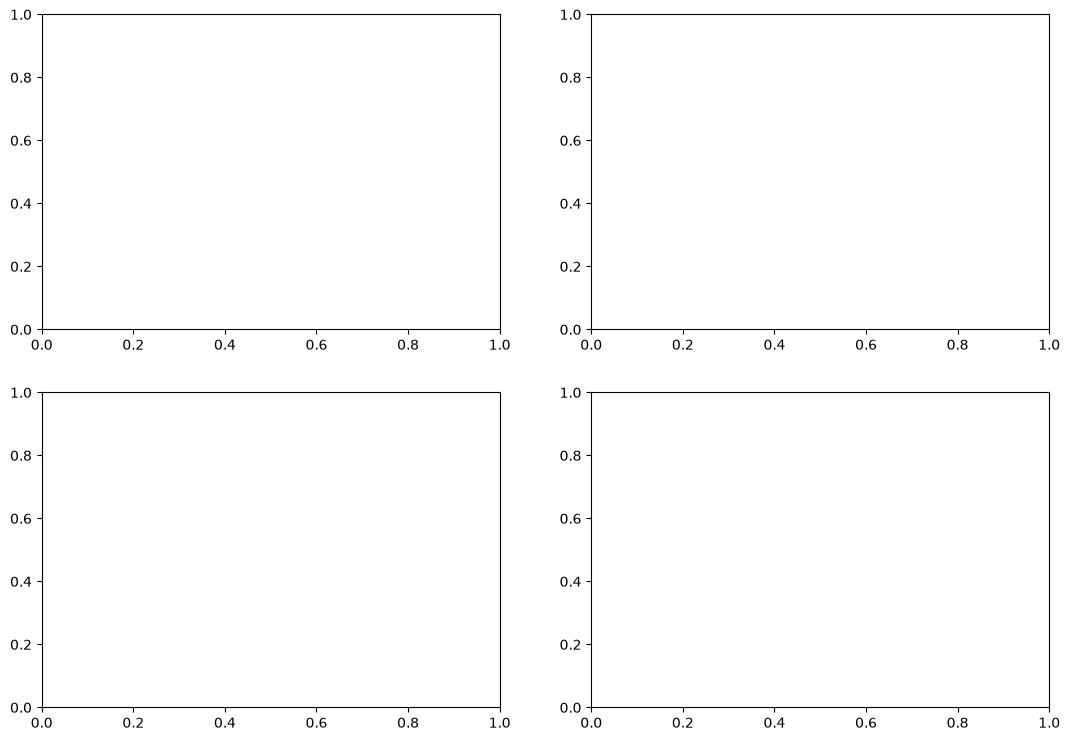

In [ ]:
import matplotlib.pyplot as plt

import pandas as pd 

df = pd.read_parquet("dataset_limpio.parquet")

df_snacks = df[df["categoria_macro"] == "Snacks y Dulces"].copy()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

graficos = [
    ('grupo_proteinas', 'fat_100g', 'Proteínas vs. Grasas'),
    ('grupo_proteinas', 'energy_kcal', 'Proteínas vs. Energía'),
    ('grupo_fibra', 'fat_100g', 'Fibra vs. Grasas'),
    ('grupo_fibra', 'energy_kcal', 'Fibra vs. Energía')
]

for ax, (grupo, variable, titulo) in zip(axes.flat, graficos):

    df_snacks.boxplot(
        column=variable,
        by=grupo,
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel('Grupo')
    ax.set_ylabel(variable)

plt.suptitle('Comparación nutricional de snacks')
plt.tight_layout()
plt.show()